In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('combined.csv',index_col='date')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39721 entries, 2022-01-01 00:00:00 to 2026-09-23 22:00:00
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   planned_consumption  39721 non-null  int64
 1   actual_consumption   39721 non-null  int64
 2   planned_generation   39721 non-null  int64
 3   actual_generation    39721 non-null  int64
 4   average_price        39721 non-null  int64
dtypes: int64(5)
memory usage: 1.8+ MB


In [3]:
df.describe()

,planned_consumption,actual_consumption,planned_generation,actual_generation,average_price
count,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000
mean,4261.351049,4260.495758,2978.338713,2971.937388,1751.918204
std,387.206145,397.910899,458.159275,462.197089,547.754144
min,3161.000000,0.000000,1524.000000,0.000000,0.000000
25%,3975.000000,3971.000000,2624.000000,2618.000000,1382.000000
50%,4251.000000,4252.000000,2964.000000,2959.000000,1696.000000
75%,4554.000000,4556.000000,3365.000000,3356.000000,2081.000000
max,5591.000000,5675.000000,4369.000000,4454.000000,6286.000000


In [4]:
(df == 0).sum(axis=0)

planned_consumption     0
actual_consumption      6
planned_generation      0
actual_generation       4
average_price          41
dtype: int64

In [5]:
clean_df = df.copy()
COLUMNS=['planned_consumption','actual_consumption','planned_generation','actual_generation','average_price']

for column in COLUMNS:
    clean_df[clean_df[column] == 0] = int(clean_df[column].mean())

(clean_df == 0).sum(axis=0)

planned_consumption    0
actual_consumption     0
planned_generation     0
actual_generation      0
average_price          0
dtype: int64

In [6]:
month_df = clean_df.loc['2023-01-01 00:00:00':'2023-01-31 22:00:00']

month_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 713 entries, 2023-01-01 00:00:00 to 2023-01-31 22:00:00
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   planned_consumption  713 non-null    int64
 1   actual_consumption   713 non-null    int64
 2   planned_generation   713 non-null    int64
 3   actual_generation    713 non-null    int64
 4   average_price        713 non-null    int64
dtypes: int64(5)
memory usage: 33.4+ KB


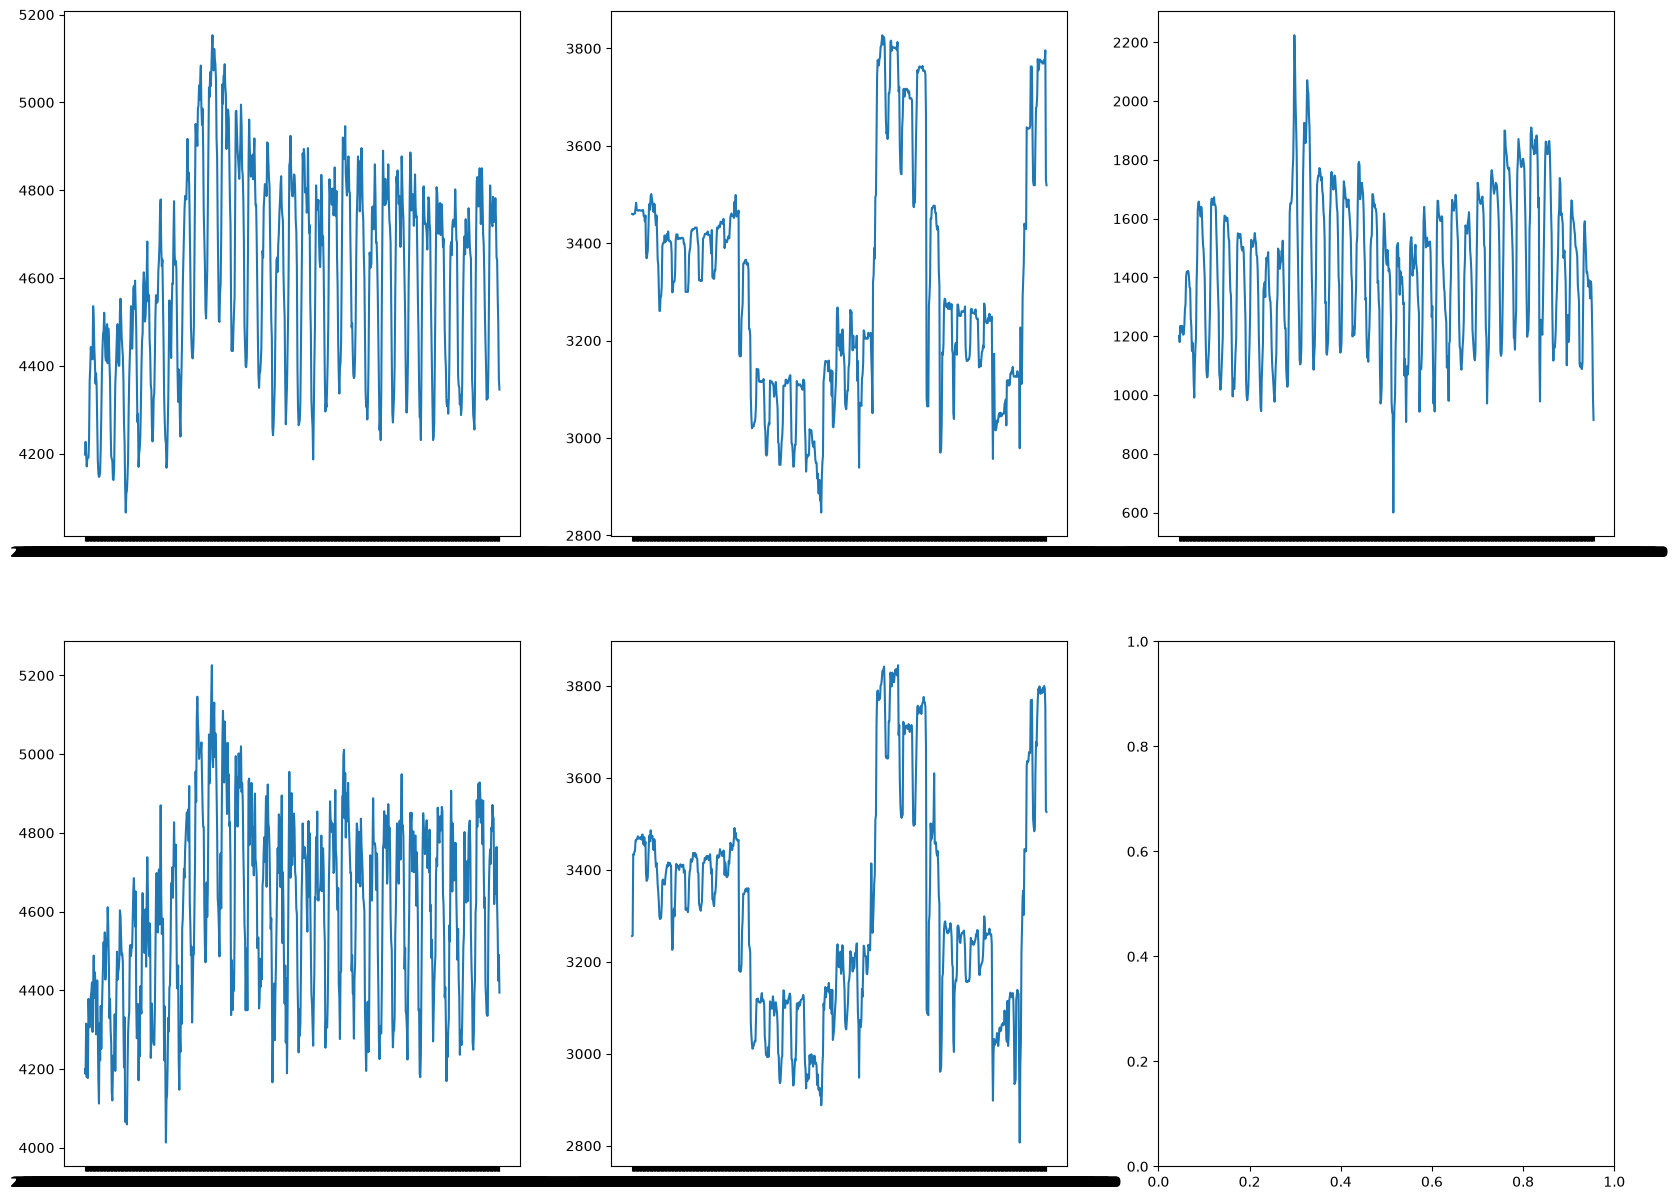

In [10]:
from math import ceil, floor

amount = len(COLUMNS)
vis_columns = 2
size = (vis_columns,ceil(amount/vis_columns))

fig, ax = plt.subplots(size[0],size[1])
fig.set_figheight(15)
fig.set_figwidth(20)

daily_index = pd.date_range(start=month_df.index.min(), 
                            end=month_df.index.max(), 
                            freq='D')

for i in range(amount):
    axis = ax[i%vis_columns,floor(i/vis_columns)]
    axis.plot(month_df[COLUMNS[i]])

plt.show()

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

COLUMNS = [
    'planned_consumption',
    'actual_consumption',
    'planned_generation',
    'actual_generation',
    'average_price'
]

DATE_COL = None       # Например: 'date', если дата хранится в столбце
LAG = 7               # Количество предыдущих дней
FORECAST_DAYS = 365   # Горизонт прогноза
RANDOM_STATE = 42

# Для проверки качества модели используем последние 365 дней.
# Если данных меньше, размер теста автоматически уменьшается.
MIN_TRAIN_DAYS = 60


# ============================================================
# 2. ПОДГОТОВКА ДАННЫХ
# ============================================================

data = df.copy()

if DATE_COL is not None:
    data[DATE_COL] = pd.to_datetime(data[DATE_COL])
    data = data.sort_values(DATE_COL).set_index(DATE_COL)
elif isinstance(data.index, pd.DatetimeIndex):
    data = data.sort_index()
else:
    # Если даты отсутствуют, считаем, что наблюдения идут
    # ежедневно и в правильном хронологическом порядке.
    data.index = pd.date_range(
        start='2000-01-01',
        periods=len(data),
        freq='D'
    )

data = data[COLUMNS].copy()
data = data.replace([np.inf, -np.inf], np.nan)

# Заполняем пропуски отдельно в каждом столбце.
# Если df уже очищен, эти строки ничего не изменят.
data = data.fillna(data.mean())

if data.isna().any().any():
    raise ValueError(
        "В данных остались пропуски. "
        "Проверьте столбцы с полностью отсутствующими значениями."
    )

if len(data) <= LAG + MIN_TRAIN_DAYS:
    raise ValueError(
        f"Недостаточно данных. Нужно более {LAG + MIN_TRAIN_DAYS} строк."
    )

values = data.to_numpy(dtype=float)
dates = pd.DatetimeIndex(data.index)

n_features = len(COLUMNS)


# ============================================================
# 3. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def calendar_features(date):
    """Календарные признаки для прогнозируемого дня."""
    day_of_week = date.dayofweek
    day_of_year = date.dayofyear

    return np.array([
        np.sin(2 * np.pi * day_of_week / 7),
        np.cos(2 * np.pi * day_of_week / 7),
        np.sin(2 * np.pi * day_of_year / 365.25),
        np.cos(2 * np.pi * day_of_year / 365.25)
    ])


# ============================================================
# 4. ФОРМИРОВАНИЕ ОБУЧАЮЩЕЙ ВЫБОРКИ
# ============================================================

def make_supervised(history, history_dates, lag=LAG):
    """
    X: значения всех пяти показателей за предыдущие lag дней
       + календарные признаки прогнозируемого дня.
    y: все пять показателей следующего дня.
    """
    X, y = [], []

    for i in range(lag, len(history)):
        past_values = history[i - lag:i].flatten()
        calendar = calendar_features(history_dates[i])

        X.append(np.concatenate([past_values, calendar]))
        y.append(history[i])

    return np.asarray(X), np.asarray(y)


# ============================================================
# 5. СОЗДАНИЕ MLP
# ============================================================

def create_model():
    return make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64, 32),
            activation='relu',
            solver='adam',
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=20,
            random_state=RANDOM_STATE
        )
    )


# ============================================================
# 6. РЕКУРСИВНЫЙ ПРОГНОЗ С ЕЖЕДНЕВНЫМ ПЕРЕОБУЧЕНИЕМ
# ============================================================

def recursive_forecast(
    initial_history,
    initial_dates,
    horizon,
    daily_retrain=True
):
    """
    На каждом шаге:
    1. Формируем обучающую выборку из доступной истории.
    2. Обучаем MLP.
    3. Прогнозируем следующий день.
    4. Добавляем прогноз в историю для следующего шага.

    Важно: после начала прогнозирования реальные будущие значения
    неизвестны, поэтому в историю добавляются предсказания модели.
    """
    history = initial_history.copy()
    history_dates = pd.DatetimeIndex(initial_dates).copy()

    predictions = []
    prediction_dates = []

    model = None

    for step in range(horizon):
        X_train, y_train = make_supervised(
            history, history_dates
        )

        if daily_retrain or model is None:
            model = create_model()
            model.fit(X_train, y_train)

        next_date = history_dates[-1] + pd.Timedelta(days=1)

        # Используем только последние LAG дней.
        lag_values = history[-LAG:].flatten()
        calendar = calendar_features(next_date)

        X_next = np.concatenate([
            lag_values,
            calendar
        ]).reshape(1, -1)

        prediction = model.predict(X_next)[0]

        predictions.append(prediction)
        prediction_dates.append(next_date)

        # Прогноз становится входом для следующего дня.
        history = np.vstack([history, prediction])
        history_dates = history_dates.append(
            pd.DatetimeIndex([next_date])
        )

        if (step + 1) % 30 == 0:
            print(
                f"Обработано дней: {step + 1}/{horizon}"
            )

    forecast_df = pd.DataFrame(
        predictions,
        index=pd.DatetimeIndex(prediction_dates),
        columns=COLUMNS
    )

    return forecast_df


# ============================================================
# 7. ХРОНОЛОГИЧЕСКАЯ ПРОВЕРКА НА ОТЛОЖЕННОМ ПЕРИОДЕ
# ============================================================

# Последний год (или доступная часть данных) не используется
# при первоначальном обучении.
test_size = min(
    FORECAST_DAYS,
    len(data) - MIN_TRAIN_DAYS
)

split_idx = len(data) - test_size

train_data = values[:split_idx]
train_dates = dates[:split_idx]

test_data = values[split_idx:]
test_dates = dates[split_idx:]

print(f"Обучающих наблюдений: {len(train_data)}")
print(f"Тестовых наблюдений: {len(test_data)}")

# Прогнозируем весь тестовый период рекурсивно.
# Фактические значения теста не передаются модели.
test_forecast = recursive_forecast(
    initial_history=train_data,
    initial_dates=train_dates,
    horizon=len(test_data),
    daily_retrain=True
)

y_true = test_data
y_pred = test_forecast.to_numpy()


# ============================================================
# 8. ТРИ СТАНДАРТНЫЕ МЕТРИКИ ОШИБКИ
# ============================================================

# Метрики по каждому столбцу, поскольку единицы измерения
# и масштабы показателей могут различаться.
metrics = pd.DataFrame(
    {
        'MAE': mean_absolute_error(
            y_true, y_pred, multioutput='raw_values'
        ),
        'MSE': mean_squared_error(
            y_true, y_pred, multioutput='raw_values'
        ),
        'RMSE': np.sqrt(
            mean_squared_error(
                y_true, y_pred, multioutput='raw_values'
            )
        )
    },
    index=COLUMNS
)

print("\nМетрики на тестовом периоде:")
print(metrics.round(4))

# Дополнительно: среднее по пяти показателям.
# Это среднее ошибок, а не ошибка в единой физической единице.
print("\nСреднее значение метрик по столбцам:")
print(metrics.mean().round(4))


# ============================================================
# 9. ПРОГНОЗ НА СЛЕДУЮЩИЕ 365 ДНЕЙ
# ============================================================

# После оценки качества используем весь доступный датасет.
future_forecast = recursive_forecast(
    initial_history=values,
    initial_dates=dates,
    horizon=FORECAST_DAYS,
    daily_retrain=True
)

print("\nПервые строки прогноза:")
print(future_forecast.head())

print("\nПоследние строки прогноза:")
print(future_forecast.tail())

# Сохраняем прогноз в CSV.
future_forecast.to_csv(
    'mlp_forecast_365_days.csv',
    index_label='date'
)

# Сохраняем метрики.
metrics.to_csv('mlp_metrics.csv', index_label='target')

print("\nФайлы сохранены:")
print("mlp_forecast_365_days.csv")
print("mlp_metrics.csv")


# ============================================================
# 10. ВИЗУАЛИЗАЦИЯ ПРОГНОЗА
# ============================================================

fig, axes = plt.subplots(
    n_features, 1,
    figsize=(15, 4 * n_features)
)

for i, column in enumerate(COLUMNS):
    ax = axes[i]

    # Последние 90 дней исходных данных
    history_window = min(90, len(data))

    ax.plot(
        data.index[-history_window:],
        data[column].iloc[-history_window:],
        label='Исторические данные'
    )

    ax.plot(
        future_forecast.index,
        future_forecast[column],
        label='Прогноз MLP на 365 дней'
    )

    ax.set_title(column)
    ax.set_xlabel('Дата')
    ax.set_ylabel(column)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 11. ВИЗУАЛИЗАЦИЯ ФАКТА И ПРОГНОЗА НА ТЕСТОВОМ ПЕРИОДЕ
# ============================================================

fig, axes = plt.subplots(
    n_features, 1,
    figsize=(15, 4 * n_features)
)

for i, column in enumerate(COLUMNS):
    ax = axes[i]

    ax.plot(
        test_dates,
        y_true[:, i],
        label='Фактические значения'
    )

    ax.plot(
        test_dates,
        y_pred[:, i],
        label='Прогноз MLP'
    )

    ax.set_title(f'Проверка модели: {column}')
    ax.set_xlabel('Дата')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Обучающих наблюдений: 39356
Тестовых наблюдений: 365


/tmp/ipykernel_55001/3932499506.py:174: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_date = history_dates[-1] + pd.Timedelta(days=1)
/tmp/ipykernel_55001/3932499506.py:174: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_date = history_dates[-1] + pd.Timedelta(days=1)
/tmp/ipykernel_55001/3932499506.py:174: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_date = history_dates[-1] + pd.Timedelta(days=1)
/tmp/ipykernel_55001/3932499506.py:174: DeprecationWarning: The 'generic'

Обработано дней: 30/365
